# Road Damage Classification — M2 and M3

**Completed experiment: `simple_v1` — 24 October 2026.** This notebook contains the saved training outputs, model comparisons, validation error analysis, data-improvement plan and final Norway test results. All experiment code is visible here; no separate Python modules are required.

**Review the saved outputs without running the cells.** Reproduction is a separate run using a new experiment folder and the recorded environment. Do not clear outputs or rerun training to make documentation edits.

The existing M1 crops and split assignments were used to compare:
1. A small CNN trained from scratch.
2. An ImageNet-pretrained ResNet18 with a frozen backbone and a new classifier.
3. An independently initialized ImageNet-pretrained ResNet18 with all layers fine-tuned.

Checkpoints and the preferred model were selected by **validation macro F1** before final testing. The selected model was **finetune, epoch 4**, with validation macro F1 **0.78494**. Its held-out Norway test accuracy was **78.45%** and macro F1 was **0.61935**. Test results were not used for model selection or subsequent tuning.

| Label | Damage |
|---|---|
| D00 | Longitudinal crack |
| D10 | Transverse crack |
| D20 | Alligator crack |
| D40 | Pothole |

The experiment used a Tesla T4, seed 42 and 224 × 224 RGB inputs. The limitations of this single-seed comparison are discussed below.


## 1. Set up Colab

This setup section is retained as part of the executed experiment. Reviewing the saved results does not require a Colab runtime.

For a fresh reproduction, select a GPU runtime and match the versions in this folder's `requirements.txt` before training. The completed environment used `torch==2.11.0+cu130`, `torchvision==0.26.0+cu130` and `scikit-learn==1.6.1`. The original setup cell below pins `wandb==0.22.3` and `protobuf==6.33.5`; its scikit-learn install argument is unpinned, so check the recorded version when reproducing the run.

The original package-export cell records eight packages. The repository requirements also include the `protobuf==6.33.5` pin from the setup cell. These documentation edits preserve the original executed code and outputs.


In [2]:
%pip -q install "wandb==0.22.3" "protobuf==6.33.5" scikit-learn

In [3]:
from pathlib import Path
from importlib.metadata import version
import json
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import wandb

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")


Device: Tesla T4


## 2. Connect Drive
The current project folder name ends with a space: **AI Project **. Keep that space in the path.
Teammates can change the paths and use a separate results folder.


In [4]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [5]:
DATA_FOLDER = "/content/drive/MyDrive/AI Project /Data" #@param {type:"string"}
RESULTS_FOLDER = "/content/drive/MyDrive/AI Project /Results/m2_m3/alharby6626" #@param {type:"string"}
EXPERIMENT = "simple_v1" #@param {type:"string"}

data_dir = Path(DATA_FOLDER)
output_dir = Path(RESULTS_FOLDER) / EXPERIMENT
output_dir.mkdir(parents=True, exist_ok=True)
assert (data_dir / "classification_manifest.csv").is_file(), "Check DATA_FOLDER."
assert (data_dir / "classification_crops.zip").is_file(), "The crop ZIP is missing."
print("Data:", data_dir)
print("Results:", output_dir)


Data: /content/drive/MyDrive/AI Project /Data
Results: /content/drive/MyDrive/AI Project /Results/m2_m3/alharby6626/simple_v1


## 3. Read the ready-made M1 data
Use the split column from the existing classification manifest. These few checks catch missing labels,
duplicate crop paths and parent images appearing in more than one split. They do not recreate M1 or change its splits.


The saved split-count table below describes the following unchanged data partitions:

| Split | Crops | Countries |
|---|---:|---|
| Training | 12,000 | India, Japan, United States |
| Validation | 9,463 | China, Czech |
| Test | 11,229 | Norway |

Training has 3,000 crops per class. Validation and test retain their existing class distributions. Manifest checks establish structural consistency; they do not establish visual label correctness.


In [6]:
classes = ["D00", "D10", "D20", "D40"]
class_to_id = {name: i for i, name in enumerate(classes)}
df = pd.read_csv(data_dir / "classification_manifest.csv")
assert df[["crop_path", "image_id", "class", "split"]].notna().all().all()
assert df["class"].isin(classes).all(), "Unknown class."
assert set(df["split"]) == {"train", "val", "test"}, "Missing or unknown split."
assert not df["crop_path"].duplicated().any(), "Duplicate crop path."
assert df.groupby("image_id")["split"].nunique().max() == 1, "Parent image crosses splits."
df["relative_path"] = df["crop_path"].str.replace("\\", "/", regex=False).str.split("classification_crops/").str[-1]
df["label"] = df["class"].map(class_to_id)
splits = {name: df[df["split"] == name].reset_index(drop=True) for name in ["train", "val", "test"]}
display(pd.crosstab(df["split"], df["class"]).reindex(["train", "val", "test"], columns=classes))


class,D00,D10,D20,D40
split,,,,
train,3000,3000,3000,3000
val,5092,2758,1095,518
test,8570,1730,468,461


Unpack the existing ZIP onto Colab's local disk for faster image loading. This does not crop images again.
The archive can contain a classification_crops folder or start directly with train/val/test.


In [7]:
local_zip = Path("/content/rdd_crops.zip")
crop_root = Path("/content/rdd_simple_crops")
shutil.copy2(data_dir / "classification_crops.zip", local_zip)

with zipfile.ZipFile(local_zip) as archive:
    for member in archive.infolist():
        if member.is_dir() or not member.filename.lower().endswith(".jpg"):
            continue
        parts = member.filename.replace("\\", "/").split("/")
        assert ".." not in parts, "Unsafe archive path."
        split, label, filename = parts[-3:]
        assert split in splits and label in classes, "Unexpected crop folder."
        target = crop_root / split / label / filename
        target.parent.mkdir(parents=True, exist_ok=True)
        with archive.open(member) as source, target.open("wb") as destination:
            shutil.copyfileobj(source, destination)

assert all((crop_root / p).is_file() for p in df["relative_path"]), "Some crops are missing."
print("Crops ready:", len(df))


Crops ready: 32692


## 4. Set training options
Use the same seed, data, image size, batch size and epoch count for all models.
Change EXPERIMENT before changing settings or restarting training.
Best checkpoints and histories are saved to Drive each epoch. This simple notebook does not resume
an interrupted optimizer. After reconnecting, rerun setup and skip training cells for completed models.


For a fresh reproduction, select a new `EXPERIMENT` name and set `FINAL_TEST_READY = False` before execution. Keep the recorded settings and evaluation protocol fixed. Enable final testing only after the validation review. The saved `True` flag in this completed notebook records the final evaluation already performed.

To inspect this completed experiment, use its saved outputs and exported reports. Its existing checkpoint and final-test guards intentionally prevent overwriting the completed run.


In [8]:
SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
IMAGE_SIZE = 224
LEARNING_RATES = {"scratch": 0.001, "frozen": 0.0003, "finetune": 0.0003}
WANDB_PROJECT = "rdd2022-road-damage"
WANDB_ENTITY = ""  # Team workspace name; blank uses your default workspace.
GROUP = "alharby6626_" + EXPERIMENT
model_names = ["scratch", "frozen", "finetune"]

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
config = dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
              optimizer="AdamW", weight_decay=0.0001, selection="val_macro_f1",
              classes=classes, data_folder=DATA_FOLDER, split="Unchanged M1 country split")
packages = ["torch", "torchvision", "numpy", "pandas", "Pillow", "matplotlib", "scikit-learn", "wandb"]
(output_dir / "requirements.txt").write_text("\n".join(f"{p}=={version(p)}" for p in packages))
print(config)


{'seed': 42, 'epochs': 10, 'batch_size': 32, 'image_size': 224, 'optimizer': 'AdamW', 'weight_decay': 0.0001, 'selection': 'val_macro_f1', 'classes': ['D00', 'D10', 'D20', 'D40'], 'data_folder': '/content/drive/MyDrive/AI Project /Data', 'split': 'Unchanged M1 country split'}


## 5. Load images
Apply horizontal flips only to training images. Both training and evaluation use 224-pixel resizing
and ImageNet normalization. Avoid random crops because M1 already cropped the damage regions.


In [9]:
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(), normalize
])

class DamageDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows, self.transform = rows.reset_index(drop=True), transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        with Image.open(crop_root / row["relative_path"]) as image:
            image = self.transform(image.convert("RGB"))
        return image, int(row["label"])

def make_loader(split, training=False):
    dataset = DamageDataset(splits[split], train_transform if training else eval_transform)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=training, num_workers=2)

val_loader = make_loader("val")
print("Image loaders are ready.")


Image loaders are ready.


## 6. Define the models
The small CNN learns from scratch. Both ResNet18 experiments independently start from the same
ImageNet weights and replace the classifier with four outputs.
This practical comparison changes both architecture and initialization; it does not isolate pretraining alone.


In [10]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 4)
        )

    def forward(self, x):
        return self.network(x)

def build_model(name, pretrained=True):
    if name == "scratch":
        return SmallCNN().to(device)
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    if name == "frozen":
        for parameter in model.parameters():
            parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 4)
    return model.to(device)


## 7. Training and prediction
Reuse the same training functions for all three models. Frozen ResNet18 keeps its BatchNorm statistics fixed
and trains only its new classifier.


In [11]:
loss_function = nn.CrossEntropyLoss()

def train_epoch(model, loader, optimizer, frozen=False):
    model.train()
    if frozen:
        model.eval()
        model.fc.train()
    total_loss, correct, count = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, correct / count


In [12]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    labels_all, probabilities_all = [], []
    total_loss = 0
    for images, labels in loader:
        logits = model(images.to(device))
        total_loss += loss_function(logits, labels.to(device)).item() * len(labels)
        labels_all.append(labels.numpy())
        probabilities_all.append(logits.softmax(1).cpu().numpy())
    y = np.concatenate(labels_all)
    probabilities = np.concatenate(probabilities_all)
    return y, probabilities, total_loss / len(y)


## 8. Track training in W&B
Sign in at the prompt. Never put your API key in code or GitHub.
Check the workspace after login; team experiments should use the intended shared workspace.


In [14]:
wandb.login()


wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize


wandb: Paste an API key from your profile and hit enter: ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: alharby6626 (alharby6626-a) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [15]:
def train_model(name):
    set_seed()
    folder = output_dir / name
    assert not (folder / "best.pt").exists(), "Checkpoint exists. Skip this cell or use a new EXPERIMENT."
    folder.mkdir(parents=True, exist_ok=True)
    model = build_model(name)
    loader = make_loader("train", training=True)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                 lr=LEARNING_RATES[name], weight_decay=0.0001)
    run_config = {**config, "model": name, "learning_rate": LEARNING_RATES[name]}
    (folder / "config.json").write_text(json.dumps(run_config, indent=2))
    history, best_f1 = [], -1
    with wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY or None,
                    group=GROUP, name=name, job_type="training", config=run_config) as run:
        (folder / "wandb_url.txt").write_text(run.url or "")
        for epoch in range(1, EPOCHS + 1):
            train_loss, train_acc = train_epoch(model, loader, optimizer, name == "frozen")
            y, p, val_loss = predict(model, val_loader)
            val_f1 = f1_score(y, p.argmax(1), labels=range(4), average="macro", zero_division=0)
            row = dict(epoch=epoch, train_loss=train_loss, train_accuracy=train_acc,
                       val_loss=val_loss, val_accuracy=float((y == p.argmax(1)).mean()), val_macro_f1=val_f1)
            history.append(row)
            run.log(row)
            if val_f1 > best_f1:
                best_f1 = val_f1
                torch.save(model.state_dict(), folder / "best.pt")
                run.summary.update({"best_val_macro_f1": best_f1, "best_epoch": epoch})
            pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
            print(f"{name} | epoch {epoch}/{EPOCHS} | val F1: {val_f1:.3f}")
    (folder / "training_complete.txt").write_text(f"Completed {EPOCHS} epochs")
    del model, optimizer
    torch.cuda.empty_cache()


## 9. Train the three models
Run each cell separately and wait until all its epochs finish.
ResNet18 downloads pretrained weights on its first use.


In [16]:
train_model("scratch")


scratch | epoch 1/10 | val F1: 0.597
scratch | epoch 2/10 | val F1: 0.560
scratch | epoch 3/10 | val F1: 0.573
scratch | epoch 4/10 | val F1: 0.628
scratch | epoch 5/10 | val F1: 0.583
scratch | epoch 6/10 | val F1: 0.623
scratch | epoch 7/10 | val F1: 0.551
scratch | epoch 8/10 | val F1: 0.630
scratch | epoch 9/10 | val F1: 0.483
scratch | epoch 10/10 | val F1: 0.575


epoch,▁▂▃▃▄▅▆▆▇█
train_accuracy,▁▄▆▆▇▇██▇█
train_loss,█▅▃▃▂▂▂▁▁▁
val_accuracy,▅▄▄▇▇▇▄█▁▁
val_loss,▃▃▄▁▁▂▄▁█▇
val_macro_f1,▆▅▅█▆█▄█▁▅
best_epoch,8
best_val_macro_f1,0.63004
epoch,10
train_accuracy,0.75025
train_loss,0.63898


In [17]:
train_model("frozen")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


frozen | epoch 1/10 | val F1: 0.685
frozen | epoch 2/10 | val F1: 0.696
frozen | epoch 3/10 | val F1: 0.702
frozen | epoch 4/10 | val F1: 0.713
frozen | epoch 5/10 | val F1: 0.722
frozen | epoch 6/10 | val F1: 0.720
frozen | epoch 7/10 | val F1: 0.713
frozen | epoch 8/10 | val F1: 0.720
frozen | epoch 9/10 | val F1: 0.719
frozen | epoch 10/10 | val F1: 0.726


epoch,▁▂▃▃▄▅▆▆▇█
train_accuracy,▁▆▆▇▇▇████
train_loss,█▃▂▂▂▁▁▁▁▁
val_accuracy,▁▃▅▆██▆▇▇█
val_loss,█▅▄▂▁▁▃▂▂▁
val_macro_f1,▁▃▄▆▇▇▆▇▇█
best_epoch,10
best_val_macro_f1,0.72635
epoch,10
train_accuracy,0.84975
train_loss,0.40776


In [18]:
train_model("finetune")


finetune | epoch 1/10 | val F1: 0.778
finetune | epoch 2/10 | val F1: 0.771
finetune | epoch 3/10 | val F1: 0.740
finetune | epoch 4/10 | val F1: 0.785
finetune | epoch 5/10 | val F1: 0.749
finetune | epoch 6/10 | val F1: 0.775
finetune | epoch 7/10 | val F1: 0.772
finetune | epoch 8/10 | val F1: 0.746
finetune | epoch 9/10 | val F1: 0.773
finetune | epoch 10/10 | val F1: 0.740


epoch,▁▂▃▃▄▅▆▆▇█
train_accuracy,▁▄▅▆▆▇▇▇██
train_loss,█▅▄▃▃▂▂▂▁▁
val_accuracy,██▅▇▆▇▇▅▇▁
val_loss,▁▁▂▂▃▂▃▆▄█
val_macro_f1,▇▆▁█▂▇▆▂▆▁
best_epoch,4
best_val_macro_f1,0.78494
epoch,10
train_accuracy,0.96475
train_loss,0.10274


## 10. Plot learning curves

**Figure context for all three panels below:** each model was trained for ten epochs on 12,000 training crops and evaluated each epoch on 9,463 validation crops from the unchanged M1 splits. Model inputs are **224 × 224 RGB**. The left plot shows mean cross-entropy loss; the right plot shows top-1 accuracy. Predictions use the highest softmax score, with no confidence-rejection threshold.

Training metrics are measured on horizontally augmented images during optimization; validation metrics use evaluation mode without random augmentation. These curves show all epochs, while final model comparisons use each model's best validation-macro-F1 checkpoint.

The frozen model shows relatively stable validation behavior. Full fine-tuning improves training performance while validation loss rises, indicating overfitting. The scratch model's validation performance is unstable. These observations support using validation checkpoint selection instead of automatically using the last epoch.


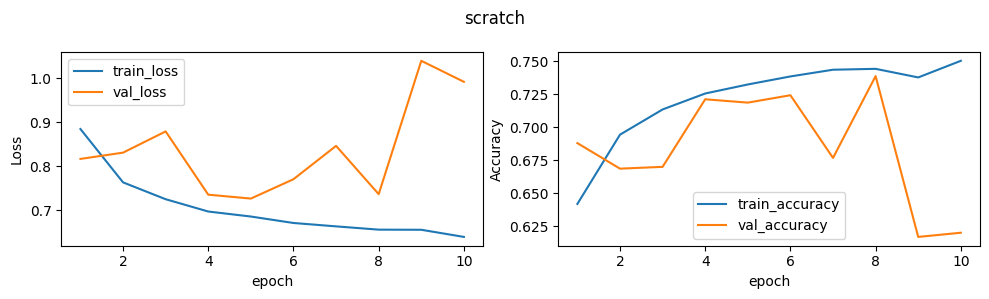

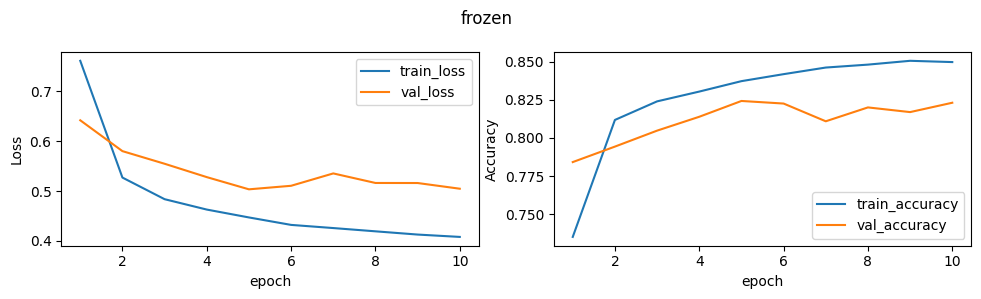

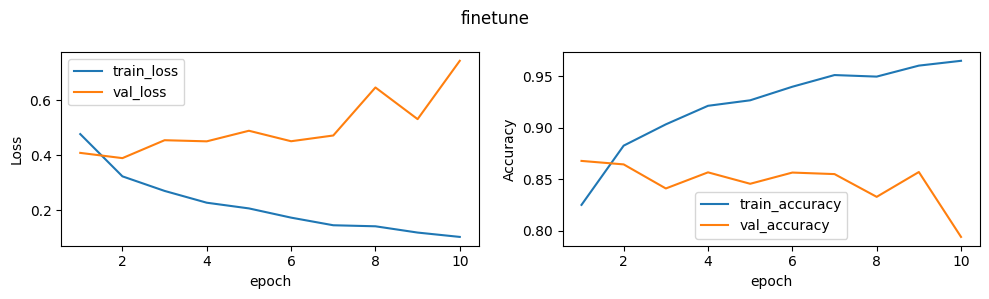

In [19]:
for name in model_names:
    history = pd.read_csv(output_dir / name / "history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0])
    history.plot(x="epoch", y=["train_accuracy", "val_accuracy"], ax=axes[1])
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Accuracy")
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(output_dir / name / "learning_curves.png", dpi=150)
    plt.show()
    plt.close(fig)


## 11. Metrics, confusion matrix and calibration
Expected calibration error (ECE) compares confidence with observed accuracy in ten equal-width bins.
Lower ECE is better; a reliability curve close to the diagonal indicates better calibration.
These are the original softmax probabilities, without temperature scaling.


For all reported classification metrics, top-1 predictions use the highest softmax score with no rejection threshold. Top-2 accuracy counts the true class appearing among the two highest scores. Confusion-matrix rows are true labels and columns are predictions; matrix entries are raw crop counts. Each evaluation's split and model context are stated alongside its results below.


In [20]:
def calibration_table(y, probabilities):
    confidence = probabilities.max(1)
    correct = probabilities.argmax(1) == y
    bins = np.minimum((confidence * 10).astype(int), 9)
    rows = []
    for b in range(10):
        mask = bins == b
        if mask.any():
            rows.append(dict(bin=b, count=int(mask.sum()),
                             confidence=float(confidence[mask].mean()), accuracy=float(correct[mask].mean())))
    table = pd.DataFrame(rows)
    ece = float((table["count"] * (table["accuracy"] - table["confidence"]).abs()).sum() / len(y))
    return table, ece


The test-accuracy confidence interval uses **1,000 bootstrap resamples of parent images**, retaining their crops together, with random seed 42. Its endpoints are the 2.5th and 97.5th percentiles of bootstrap accuracy. It describes uncertainty within the Norway sample, not variation across countries or training seeds.


In [21]:
def accuracy_interval(rows, correct):
    grouped = pd.DataFrame({"image_id": rows["image_id"].to_numpy(), "correct": correct})
    counts = grouped.groupby("image_id")["correct"].agg(["sum", "count"]).to_numpy()
    rng = np.random.default_rng(SEED)
    scores = []
    for _ in range(1000):
        sample = counts[rng.integers(0, len(counts), len(counts))].sum(axis=0)
        scores.append(sample[0] / sample[1])
    return np.quantile(scores, [0.025, 0.975]).tolist()


In [22]:
def save_plots(y, prediction, calibration, folder):
    matrix = confusion_matrix(y, prediction, labels=range(4))
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set(xticks=range(4), yticks=range(4), xticklabels=classes, yticklabels=classes,
           xlabel="Predicted", ylabel="True", title="Confusion matrix")
    fig.tight_layout()
    fig.savefig(folder / "confusion_matrix.png", dpi=150)
    plt.close(fig)
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(folder / "confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot([0, 1], [0, 1], "--", label="Ideal")
    ax.plot(calibration["confidence"], calibration["accuracy"], "o-", label="Model")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Accuracy", title="Reliability diagram")
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "reliability.png", dpi=150)
    plt.close(fig)


In [23]:
def evaluate_model(name, split):
    model_folder = output_dir / name
    assert (model_folder / "training_complete.txt").exists(), f"Finish training {name} first."
    model = build_model(name, pretrained=False)
    model.load_state_dict(torch.load(model_folder / "best.pt", map_location=device, weights_only=True))
    y, p, loss = predict(model, make_loader(split))
    prediction = p.argmax(1)
    folder = model_folder / split
    folder.mkdir(parents=True, exist_ok=True)
    report = pd.DataFrame(classification_report(y, prediction, labels=range(4), target_names=classes,
                                               output_dict=True, zero_division=0)).T
    report.to_csv(folder / "per_class_metrics.csv")
    calibration, ece = calibration_table(y, p)
    calibration.to_csv(folder / "calibration_bins.csv", index=False)
    save_plots(y, prediction, calibration, folder)
    metrics = dict(accuracy=float((prediction == y).mean()),
                   top2_accuracy=float((np.argsort(-p, axis=1, kind="stable")[:, :2] == y[:, None]).any(1).mean()),
                   macro_f1=float(report.loc["macro avg", "f1-score"]), ece=ece, loss=loss)
    if split == "test":
        metrics["accuracy_ci95_low"], metrics["accuracy_ci95_high"] = accuracy_interval(splits[split], prediction == y)
    (folder / "metrics.json").write_text(json.dumps(metrics, indent=2))
    predictions = splits[split].copy()
    predictions["predicted"] = np.array(classes)[prediction]
    predictions["confidence"] = p.max(1)
    predictions.to_csv(folder / "predictions.csv", index=False)
    del model
    torch.cuda.empty_cache()
    return metrics, report, predictions


In [24]:
def log_evaluation(name, split, metrics, report):
    folder = output_dir / name / split
    with wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY or None, group=GROUP,
                    name=f"{name}-{split}", job_type="evaluation",
                    config={**config, "model": name, "split": split}) as run:
        run.summary.update({f"{split}/{key}": value for key, value in metrics.items()})
        run.log({"per_class_metrics": wandb.Table(dataframe=report.loc[classes].reset_index()),
                 "confusion_matrix": wandb.Image(str(folder / "confusion_matrix.png")),
                 "reliability": wandb.Image(str(folder / "reliability.png")),
                 "learning_curves": wandb.Image(str(output_dir / name / "learning_curves.png"))})
        (folder / "wandb_url.txt").write_text(run.url or "")


## 12. Compare validation results

**Table context:** all three models are evaluated on the same **9,463 validation crops from China and Czech**, using **224 × 224 RGB inputs** and each model's best validation-macro-F1 checkpoint. Top-1 classification uses the highest softmax score without a rejection threshold; top-2 accuracy uses the two highest scores. ECE uses ten equal-width bins of uncalibrated softmax confidence.

Macro F1 gives equal weight to the four classes. All experiments are recorded in one W&B group. The highest validation macro F1 determines the preferred model; the first model wins an exact tie. This comparison does not read test images.

The saved comparison selected **finetune, epoch 4**, before final testing.


In [25]:
validation_rows = []
for name in model_names:
    metrics, report, predictions = evaluate_model(name, "val")
    log_evaluation(name, "val", metrics, report)
    validation_rows.append({"model": name, **metrics})
comparison = pd.DataFrame(validation_rows)
comparison.to_csv(output_dir / "validation_comparison.csv", index=False)
selected_model = comparison.loc[comparison["macro_f1"].idxmax(), "model"]
with wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY or None,
                group=GROUP, name="validation-comparison", job_type="comparison") as run:
    run.log({"validation_comparison": wandb.Table(dataframe=comparison)})
    run.summary["selected_model"] = selected_model
display(comparison)
print("Selected using validation macro F1:", selected_model)


val/accuracy,0.73867
val/ece,0.01737
val/loss,0.73634
val/macro_f1,0.63004
val/top2_accuracy,0.88175


val/accuracy,0.8231
val/ece,0.01014
val/loss,0.50459
val/macro_f1,0.72635
val/top2_accuracy,0.93512


val/accuracy,0.85649
val/ece,0.0576
val/loss,0.45084
val/macro_f1,0.78494
val/top2_accuracy,0.96481


selected_model,finetune


,model,accuracy,top2_accuracy,macro_f1,ece,loss
0,scratch,0.738666,0.881750,0.630039,0.017365,0.736345
1,frozen,0.823100,0.935116,0.726351,0.010137,0.504589
2,finetune,0.856494,0.964810,0.784935,0.057599,0.450840


Selected using validation macro F1: finetune


## 13. Inspect validation errors and write the improvement plan

**Gallery context:** the eight most confident mistakes of the selected **finetune, epoch 4** checkpoint on the **9,463-crop China/Czech validation split**. Predictions used **224 × 224 RGB inputs**, the highest softmax score and no rejection threshold. The displayed pictures are the saved M1 crops; model input resizing occurs in the data loader.

The error-count table lists the five most frequent true/predicted confusion pairs as raw counts. The CSV contains all validation mistakes. The gallery is deliberately selected by confidence and is not a representative sample of predictions. Confidence is displayed to two decimal places.

The written analysis below connects visible examples to proposed improvements in training data without changing validation or test labels.


class  predicted
D00    D20          428
       D10          230
D10    D20          121
D20    D40           85
D40    D00           84
Name: count, dtype: int64

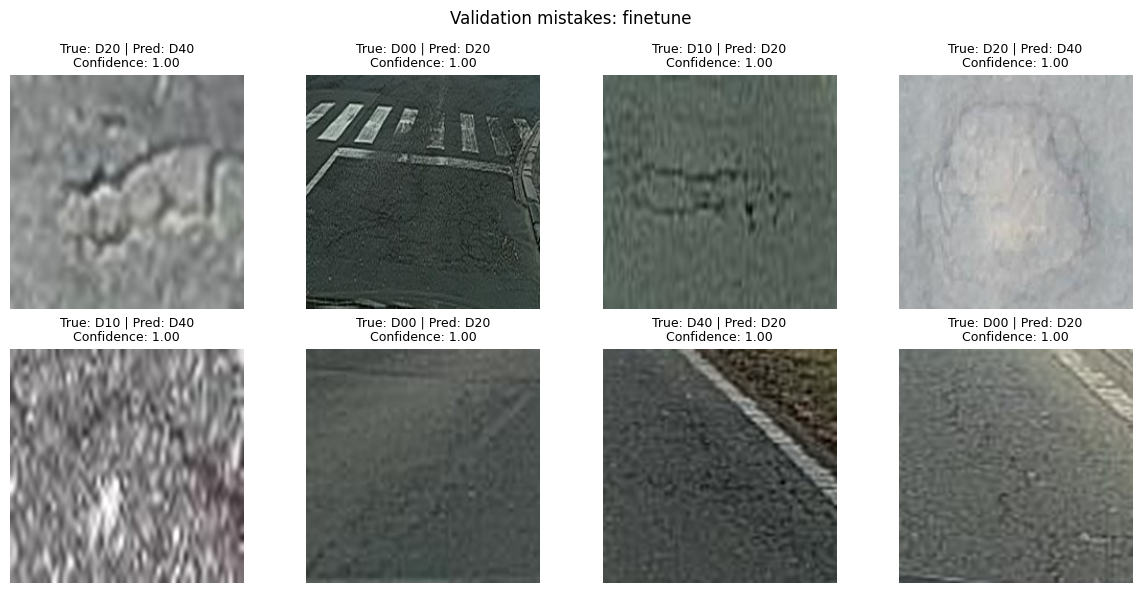

In [26]:
predictions = pd.read_csv(output_dir / selected_model / "val" / "predictions.csv")
errors = predictions[predictions["class"] != predictions["predicted"]].sort_values("confidence", ascending=False)
errors.to_csv(output_dir / "validation_errors.csv", index=False)
display(errors.groupby(["class", "predicted"]).size().rename("count").sort_values(ascending=False).head(5))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, errors.head(8).iterrows()):
    with Image.open(crop_root / row["relative_path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"True: {row['class']} | Pred: {row['predicted']}\nConfidence: {row['confidence']:.2f}", fontsize=9)
fig.suptitle(f"Validation mistakes: {selected_model}")
fig.tight_layout()
fig.savefig(output_dir / "error_gallery.png", dpi=150)
plt.show()
plt.close(fig)


### Validation analysis and data-improvement plan

We selected the fine-tuned ResNet18 checkpoint from epoch 4 using validation macro F1. It achieved **0.78494 macro F1** and **85.65% accuracy**. Its validation ECE was **0.05760**, compared with **0.01014** for the frozen model. The fine-tuned model performed better in classification, while the frozen model had lower calibration error.

The most frequent confusion was **D00 → D20 (428 crops)**, followed by **D00 → D10 (230 crops)**. These are raw counts; validation classes have different sizes, so per-class metrics must also be considered.

Several displayed crops appear blurry or have low contrast. The second image in the top row also contains prominent road markings. These observations identify cases for investigation; they do not establish that the labels are wrong.

All eight displayed errors have confidence rounded to **1.00**. They were deliberately selected as the most confident mistakes and are not representative of all predictions.

| Observed issue and example | Proposed training-data improvement | Validation check |
|---|---|---|
| D00 confused with D20; top-row image 2 and bottom-row images 2 and 4 | Add diverse training examples of longitudinal and alligator cracks, including road markings and textured backgrounds. Review ambiguous training labels against the original images. | Compare D00 recall, D20 precision, and the D00-to-D20 error rate. |
| Blurry or low-contrast damage; top-row images 1 and 3 and bottom-row image 1 | Add clearer training examples and examples covering varied lighting and sharpness. Test mild blur and contrast augmentation that preserves the damage label. | Compare per-class F1 and confusion rates on the unchanged validation set. |
| Very confident mistakes and increasing validation loss during full fine-tuning | Expand training examples with difficult crack and pothole appearances from diverse locations. | Compare macro F1, ECE, and reliability plots together. |

These improvements are proposed future experiments. Validation and test labels will remain unchanged.

Training and validation use different countries, which may contribute to the performance gap. Crop resizing may also reduce useful detail. Results come from one training seed. The M1 label-audit records require reconciliation before reporting a label-error percentage.

The selected model and checkpoints are fixed before final testing. Test results will be used for reporting, not model selection.

## 14. Final test — completed after validation review

Model choices were fixed before the final evaluation. The table below compares the three fixed best checkpoints on **11,229 held-out Norway test crops**, using **224 × 224 RGB inputs**. Top-1 predictions use the highest softmax score without a rejection threshold; top-2 accuracy uses the two highest scores. ECE uses ten equal-width confidence bins. Accuracy confidence intervals resample parent images 1,000 times.

The preferred model remains the **finetune checkpoint from epoch 4**, selected using validation macro F1. No model was selected or tuned using test results.

The completed test outputs are saved below. Review them without rerunning this cell. For a fresh reproduction, first set `FINAL_TEST_READY = False`, use a new experiment folder and follow the validation-first protocol.


In [28]:
FINAL_TEST_READY = True #@param {type:"boolean"}
if FINAL_TEST_READY:
    assert not (output_dir / "test_comparison.csv").exists(), "Final test already saved; read that CSV."
    test_rows = []
    for name in model_names:
        metrics, report, predictions = evaluate_model(name, "test")
        log_evaluation(name, "test", metrics, report)
        test_rows.append({"model": name, "selected_by_validation": name == selected_model, **metrics})
    test_comparison = pd.DataFrame(test_rows)
    test_comparison.to_csv(output_dir / "test_comparison.csv", index=False)
    with wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY or None,
                    group=GROUP, name="test-comparison", job_type="comparison") as run:
        run.log({"test_comparison": wandb.Table(dataframe=test_comparison)})
        run.summary["selected_by_validation"] = selected_model
    display(test_comparison)
else:
    print("Test is closed. Complete validation review first.")


test/accuracy,0.54546
test/accuracy_ci95_high,0.55849
test/accuracy_ci95_low,0.53282
test/ece,0.08334
test/loss,0.9678
test/macro_f1,0.42669
test/top2_accuracy,0.86891


test/accuracy,0.57316
test/accuracy_ci95_high,0.58629
test/accuracy_ci95_low,0.56101
test/ece,0.15102
test/loss,1.02136
test/macro_f1,0.48508
test/top2_accuracy,0.90284


test/accuracy,0.78449
test/accuracy_ci95_high,0.79443
test/accuracy_ci95_low,0.77456
test/ece,0.06534
test/loss,0.61028
test/macro_f1,0.61935
test/top2_accuracy,0.94879


selected_by_validation,finetune


,model,selected_by_validation,accuracy,top2_accuracy,macro_f1,ece,loss,accuracy_ci95_low,accuracy_ci95_high
0,scratch,False,0.545463,0.868911,0.426692,0.083344,0.967799,0.532819,0.558487
1,frozen,False,0.573159,0.902841,0.485077,0.151021,1.021361,0.561010,0.586286
2,finetune,True,0.784487,0.948793,0.619348,0.065339,0.610277,0.774557,0.794425


,precision,recall,f1-score,support
D00,0.9779,0.7697,0.8614,8570.0000
D10,0.8188,0.9012,0.8580,1730.0000
D20,0.3127,0.5726,0.4045,468.0000
D40,0.2240,0.8373,0.3535,461.0000
accuracy,0.7845,0.7845,0.7845,0.7845
macro avg,0.5834,0.7702,0.6193,11229.0000
weighted avg,0.8947,0.7845,0.8210,11229.0000


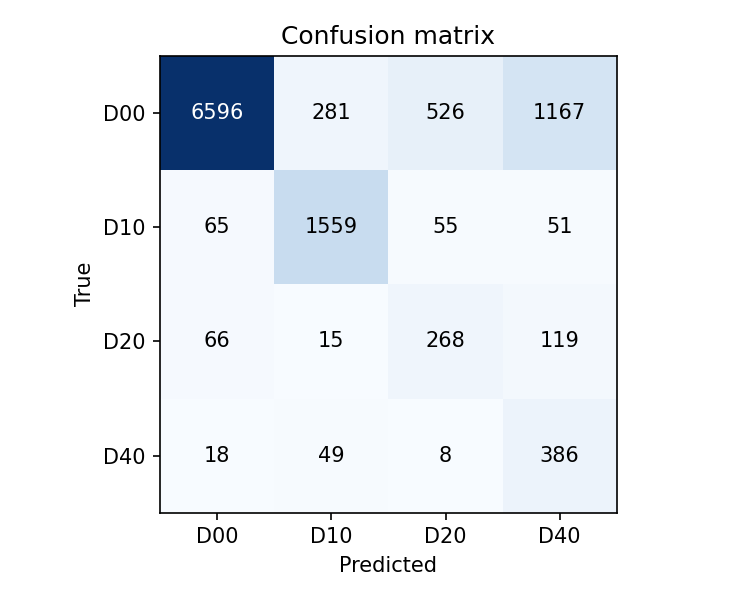

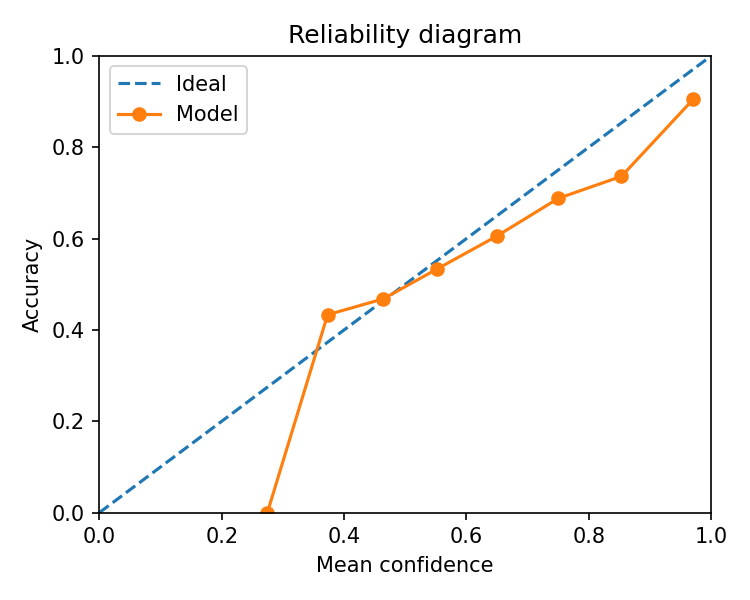

In [29]:
from IPython.display import Image as DisplayImage

test_folder = output_dir / selected_model / "test"

display(
    pd.read_csv(test_folder / "per_class_metrics.csv", index_col=0).round(4)
)

for filename in ("confusion_matrix.png", "reliability.png"):
    display(DisplayImage(filename=str(test_folder / filename)))

### Final test interpretation

**Figure context for the per-class table and two plots immediately above:** selected **finetune checkpoint, epoch 4**; **11,229 Norway test crops**; **224 × 224 RGB inputs**; highest-softmax classification without a rejection threshold. The confusion matrix shows raw counts, with true labels in rows and predictions in columns. The reliability diagram compares mean softmax confidence with observed accuracy in ten equal-width bins, plotting occupied bins only. No temperature scaling was applied.


The fine-tuned ResNet18, selected using validation macro F1 before testing, achieved **78.45% accuracy**, **0.61935 macro F1**, and **94.88% top-2 accuracy** on the held-out Norway test set. The 95% accuracy confidence interval was **77.46%–79.44%**, estimated by bootstrapping parent images.

Performance varied across classes:

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| D00 — Longitudinal crack | 0.9779 | 0.7697 | 0.8614 |
| D10 — Transverse crack | 0.8188 | 0.9012 | 0.8580 |
| D20 — Alligator crack | 0.3127 | 0.5726 | 0.4045 |
| D40 — Pothole | 0.2240 | 0.8373 | 0.3535 |

The largest test confusion was **D00 → D40**, with **1,167 crops**. Although pothole recall was relatively high, its low precision indicates many false-positive pothole predictions.

The test set is imbalanced: D00 accounts for **8,570 of 11,229 crops**, approximately **76.32%**. Macro F1 and per-class metrics therefore provide important information beyond overall accuracy.

Test ECE was **0.06534**. The reliability diagram shows that higher-confidence bins fall below the ideal diagonal, indicating overconfidence in those bins.

Macro F1 decreased from **0.78494 on validation** to **0.61935 on test**. Differences in countries, image appearance, and class distributions may contribute to this generalization gap; these results do not isolate a single cause.

The fine-tuned model also obtained higher test macro F1 than the scratch model (**0.42669**) and frozen model (**0.48508**). Model selection remained based on validation, and no models were adjusted using test results. These results represent one training seed.


## Experiment records and handover

### Completed records

- Saved training outputs and learning curves for scratch, frozen and finetune.
- Validation and test comparisons with top-1/top-2 accuracy, macro F1, ECE and loss.
- Per-class precision/recall/F1, confusion matrices and reliability diagrams in the evaluation exports and W&B runs.
- The selected model's test per-class table and diagnostic plots displayed above.
- Validation error analysis, a proposed data-improvement plan, and final test interpretation.
- A parent-image bootstrap confidence interval and documented limitations of the single-seed experiment.

### W&B traceability

- [Project](https://wandb.ai/alharby6626-a/rdd2022-road-damage)
- Group: `alharby6626_simple_v1`
- [Validation comparison](https://wandb.ai/alharby6626-a/rdd2022-road-damage/runs/21x5c025)
- [Test comparison](https://wandb.ai/alharby6626-a/rdd2022-road-damage/runs/upe9cn2v)

The original training and evaluation run links are also retained in their saved cell outputs.

### Checkpoints and reproduction

The completed experiment used:

`/content/drive/MyDrive/AI Project /Results/m2_m3/alharby6626/simple_v1`

The selected checkpoint is `finetune/best.pt` within that experiment folder. Each model also has a saved configuration, history, checkpoint and evaluation reports. The `AI Project ` directory name ends with a space; reproduction paths are editable in section 2.

Keep datasets, checkpoints and credentials outside GitHub. Retain the notebook with its outputs and the environment files inside `road_damage_m2_m3_colab` on the working branch. Record the final submitted commit in the team's submission. Reviewer access to W&B and Drive checkpoints, and an independent teammate reproduction, still require confirmation.

### Documentation revision

This revision updates explanatory Markdown, figure context and handover information. All original code cells, execution counts, outputs and embedded images were preserved; no training or evaluation was rerun.

References: [ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html),
[classification metrics](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html),
[W&B logging](https://docs.wandb.ai/models/track/log).
